In [21]:
import cv2
from ultralytics import YOLO
from IPython.display import display, Image
model = YOLO("best_v2.pt")
print(model.names)

{0: 'face-dection'}


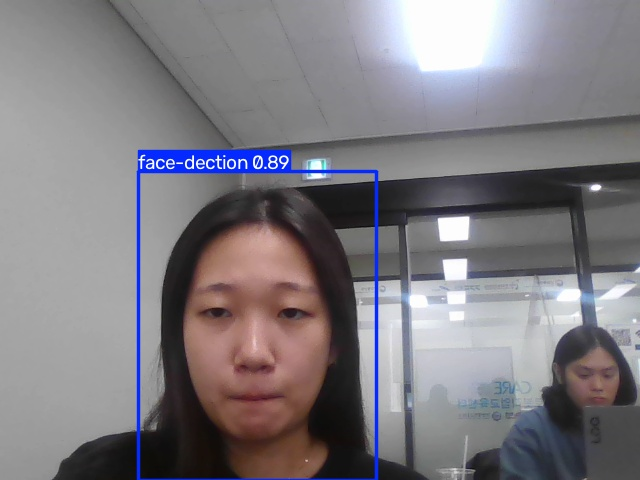

중지했습니다.


In [22]:
cap = cv2.VideoCapture(0) # 0번 카메라 = 기본 웹캠
if not cap.isOpened():
    raise RuntimeError("웹캠을 열 수 없습니다. 다른 앱이 쓰고 있는지 확인하세요.")
handle = display(None, display_id=True) # 이미지를 같은 자리에서 계속 갱신할 칸

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
    
        results = model(frame, conf=0.7, verbose=False)
        result_frame = results[0].plot() # 박스와 라벨이 그려진 프레임
        _, jpg = cv2.imencode(".jpg", result_frame)
        handle.update(Image(data=jpg.tobytes()))

except KeyboardInterrupt:
    print("중지했습니다.")
finally:
    cap.release()